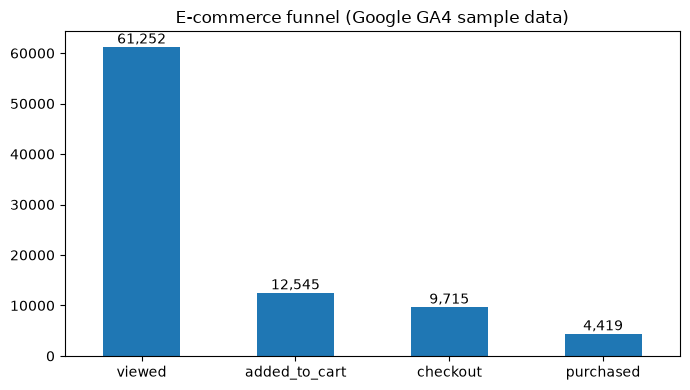

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

f = pd.read_csv('../data/funnel.csv')
steps = ['viewed', 'added_to_cart', 'checkout', 'purchased']
vals = f.loc[0, steps]

ax = vals.plot(kind='bar', figsize=(7,4), rot=0,
               title='E-commerce funnel (Google GA4 sample data)')
for i, v in enumerate(vals):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.tight_layout(); plt.savefig('../docs/charts/5_funnel.png', dpi=150); plt.show()

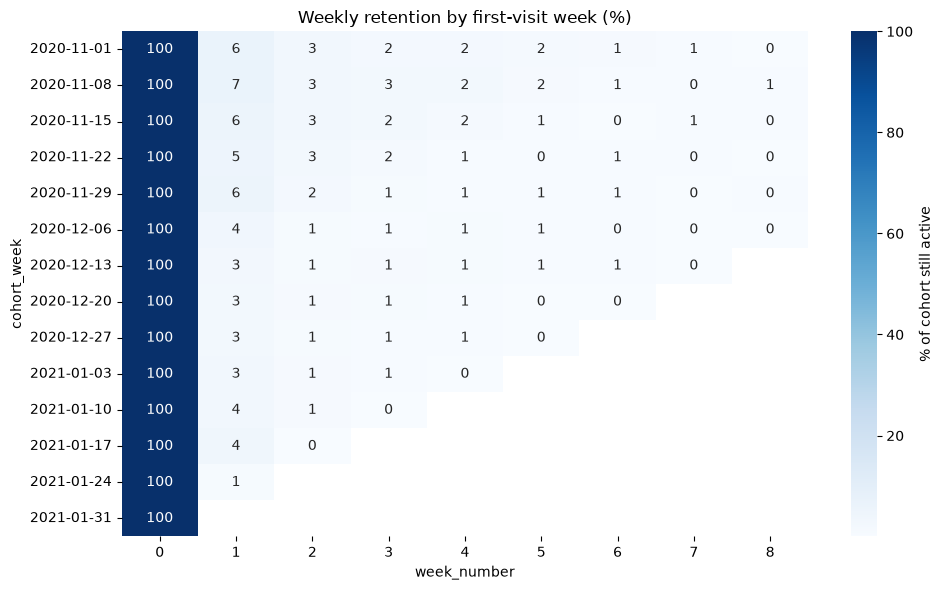

In [2]:
r = pd.read_csv('../data/retention.csv')
pivot = r.pivot(index='cohort_week', columns='week_number', values='users')
ret = pivot.div(pivot[0], axis=0) * 100
ret = ret.loc[:, 0:8]

plt.figure(figsize=(10,6))
sns.heatmap(ret, annot=True, fmt='.0f', cmap='Blues',
            cbar_kws={'label': '% of cohort still active'})
plt.title('Weekly retention by first-visit week (%)')
plt.tight_layout(); plt.savefig('../docs/charts/6_retention.png', dpi=150); plt.show()

In [3]:
print(ret[[1, 2, 4]].mean().round(1))

week_number
1    4.1
2    1.8
4    1.1
dtype: float64
